# SMS Spam Classifier (corrected version)
**Goal:** read an SMS and predict **Spam (1)** or **Not Spam / Ham (0)**.

**Steps:** load data → clean → explore → preprocess text → split → compare models → check properly → save → predict on new messages.

## Cell 1: Import libraries

In [1]:
import re
import pickle
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

import nltk
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB, BernoulliNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay)

nltk.download('stopwords')   # list of common words like 'is', 'the', 'and'

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\Dell\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

## Cell 2: Load the data
The file has 2 useful columns (`v1` = label, `v2` = message). We read only those 2, so we don't have to delete the empty `Unnamed` columns later.

In [2]:
df = pd.read_csv('spam_utf-8.txt', usecols=[0, 1], encoding='utf-8')
df.columns = ['label', 'text']      # give friendly names
df.head()

,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## Cell 3: Clean the data
Turn labels into numbers (ham = 0, spam = 1), check for missing values, and remove duplicate messages.

In [3]:
df['target'] = df['label'].map({'ham': 0, 'spam': 1})

print('Missing values:\n', df.isnull().sum())
print('Duplicate rows:', df.duplicated().sum())

df = df.drop_duplicates(keep='first').reset_index(drop=True)
print('Rows after removing duplicates:', df.shape[0])

Missing values:
 label     0
text      0
target    0
dtype: int64
Duplicate rows: 403
Rows after removing duplicates: 5169


## Cell 4: Look at class balance
If spam is much rarer than ham, then *accuracy alone* can fool us. That's why we'll also check precision, recall and F1 later.

target
0    4516
1     653
Name: count, dtype: int64


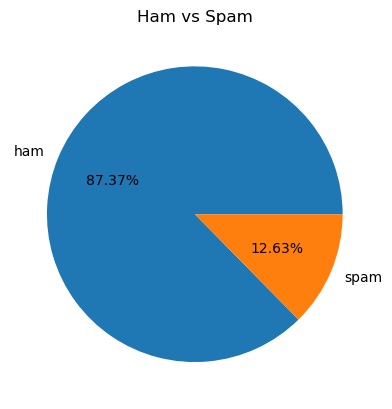

In [4]:
counts = df['target'].value_counts()
print(counts)

plt.pie(counts, labels=['ham', 'spam'], autopct='%0.2f%%')
plt.title('Ham vs Spam')
plt.show()

## Cell 5: Simple message statistics
Do spam messages look different in length?

In [5]:
df['num_char'] = df['text'].apply(len)                              # number of characters
df['num_word'] = df['text'].apply(lambda x: len(x.split()))         # number of words

print('HAM:');  print(df[df['target'] == 0][['num_char', 'num_word']].describe().loc[['mean', 'max']])
print('SPAM:'); print(df[df['target'] == 1][['num_char', 'num_word']].describe().loc[['mean', 'max']])

HAM:
        num_char    num_word
mean   70.459256   14.134632
max   910.000000  171.000000
SPAM:
        num_char  num_word
mean  137.891271  23.68147
max   224.000000  35.00000


## Cell 6: Text preprocessing function
For every message we will:
1. make it lowercase
2. keep only words/numbers (drops punctuation and symbols)
3. remove stop words (`is`, `the`, `and` ...)
4. stem words (`winning`, `wins` → `win`)

*Improvement:* the stop-word list is created **once** outside the function. The original rebuilt it for every single word, which is very slow.

In [6]:
stop_words = set(stopwords.words('english'))
stemmer = PorterStemmer()

def transform_text(text):
    text = text.lower()
    words = re.findall(r'[a-z0-9]+', text)                  # keep letters and digits only
    words = [w for w in words if w not in stop_words]       # remove stop words
    words = [stemmer.stem(w) for w in words]                # reduce to root form
    return ' '.join(words)

# quick test
transform_text('I Loved the yt lectures on Machine learning. How about you?')

'love yt lectur machin learn'

In [7]:
df['transformed_text'] = df['text'].apply(transform_text)
df[['text', 'transformed_text']].head()

,text,transformed_text
0,"Go until jurong point, crazy.. Available only ...",go jurong point crazi avail bugi n great world...
1,Ok lar... Joking wif u oni...,ok lar joke wif u oni
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entri 2 wkli comp win fa cup final tkt 21...
3,U dun say so early hor... U c already then say...,u dun say earli hor u c alreadi say
4,"Nah I don't think he goes to usf, he lives aro...",nah think goe usf live around though


## Cell 7: Most common words in spam vs ham

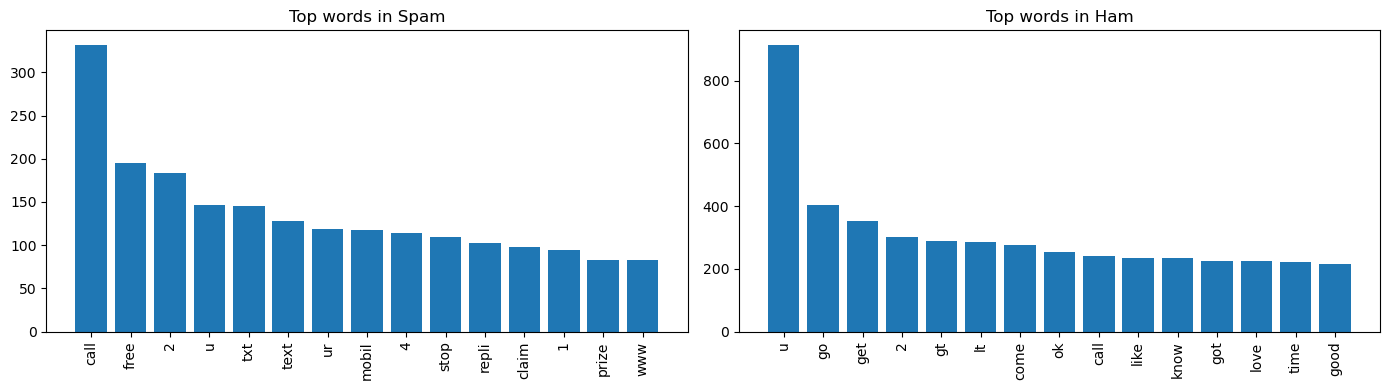

In [8]:
def top_words(target_value, n=15):
    words = ' '.join(df[df['target'] == target_value]['transformed_text']).split()
    return pd.DataFrame(Counter(words).most_common(n), columns=['word', 'count'])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (value, name) in zip(axes, [(1, 'Spam'), (0, 'Ham')]):
    t = top_words(value)
    ax.bar(t['word'], t['count'])
    ax.set_title(f'Top words in {name}')
    ax.tick_params(axis='x', rotation=90)
plt.tight_layout()
plt.show()

## Cell 8: Split into train and test (BEFORE vectorizing)
**Why this matters:** TF-IDF learns its vocabulary from the data it sees. If it learns from *all* messages, it has secretly seen the test set (called *data leakage*), and the scores look slightly better than they truly are.

`stratify=y` keeps the same spam percentage in train and test, which is important because spam is rare.

In [9]:
X = df['transformed_text']
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=2, stratify=y
)
print('Train size:', len(X_train), '| Test size:', len(X_test))

Train size: 4135 | Test size: 1034


## Cell 9: Compare several models
Each model is wrapped in a **Pipeline**: `TF-IDF → model`. The pipeline learns TF-IDF only from training data, and later does the same steps automatically on new messages.

We print **precision** (of messages called spam, how many really are?), **recall** (of real spam, how many did we catch?) and **F1** (balance of both).

In [10]:
def make_pipeline(model):
    return Pipeline([
        ('tfidf', TfidfVectorizer(max_features=3000)),
        ('model', model)
    ])

models = {
    'MultinomialNB':      MultinomialNB(),
    'BernoulliNB':        BernoulliNB(),
    'LogisticRegression': LogisticRegression(max_iter=1000),
    'RandomForest':       RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1),
}

# Ensemble: several models vote together ('soft' = average their probabilities)
models['Ensemble (Voting)'] = VotingClassifier(
    estimators=[
        ('mnb', MultinomialNB()),
        ('bnb', BernoulliNB()),
        ('lr',  LogisticRegression(max_iter=1000)),
        ('rf',  RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)),
    ],
    voting='soft'
)

results = []
fitted = {}
for name, model in models.items():
    pipe = make_pipeline(model)
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted[name] = pipe
    results.append({
        'Model': name,
        'Accuracy':  accuracy_score(y_test, pred),
        'Precision': precision_score(y_test, pred),
        'Recall':    recall_score(y_test, pred),
        'F1':        f1_score(y_test, pred),
    })

results_df = pd.DataFrame(results).sort_values('F1', ascending=False).round(4)
results_df

,Model,Accuracy,Precision,Recall,F1
1,BernoulliNB,0.9903,1.0000,0.9237,0.9603
4,Ensemble (Voting),0.9903,1.0000,0.9237,0.9603
3,RandomForest,0.9845,0.9752,0.9008,0.9365
0,MultinomialNB,0.9807,1.0000,0.8473,0.9174
2,LogisticRegression,0.9691,0.9806,0.7710,0.8632


## Cell 10: Look at the best model's mistakes
The confusion matrix shows how many messages were classified correctly and wrongly.

Best model by F1: BernoulliNB


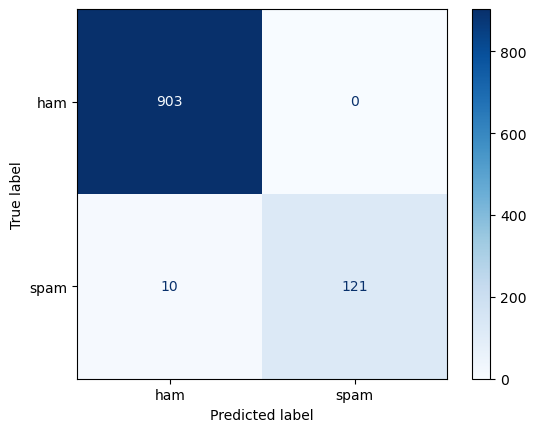

In [11]:
best_name = results_df.iloc[0]['Model']
best_pipe = fitted[best_name]
print('Best model by F1:', best_name)

ConfusionMatrixDisplay.from_estimator(
    best_pipe, X_test, y_test, display_labels=['ham', 'spam'], cmap='Blues'
)
plt.show()

## Cell 11: Double-check with cross-validation
One train/test split can be lucky or unlucky. Cross-validation trains and tests **5 times** on different slices of the data. If the scores are similar every time, we can trust the result.

In [12]:
cv_scores = cross_val_score(make_pipeline(models[best_name]), X, y, cv=5, scoring='f1')
print('F1 for each fold:', cv_scores.round(4))
print('Average F1:', cv_scores.mean().round(4))

F1 for each fold: [0.9562 0.9231 0.9091 0.9046 0.9121]
Average F1: 0.921


## Cell 12: Save the model
We save the **whole pipeline** (TF-IDF + model) in ONE file, so the vectorizer and model can never get mismatched.

In [13]:
with open('spam_model.pkl', 'wb') as f:
    pickle.dump(best_pipe, f)
print('Saved spam_model.pkl')

Saved spam_model.pkl


## Cell 13: Predict on brand-new messages
The saved model expects text that went through `transform_text` first, so we do that step before predicting.
(In your website/app, keep a copy of `transform_text` too.)

In [14]:
def predict_message(message, pipeline):
    cleaned = transform_text(message)
    label = pipeline.predict([cleaned])[0]
    spam_chance = pipeline.predict_proba([cleaned])[0][1]
    return ('SPAM' if label == 1 else 'NOT SPAM'), round(spam_chance * 100, 1)

with open('spam_model.pkl', 'rb') as f:
    loaded_model = pickle.load(f)

test_messages = [
    'Congratulations! You have won a prize of 10,00,000. Call now to claim',
    'Hey, are we still meeting for lunch at 1?',
    'URGENT! Your account is blocked. Click the link to verify now',
    'Can you send me the notes from yesterday class?',
]

for msg in test_messages:
    label, chance = predict_message(msg, loaded_model)
    print(f'{label:9} ({chance}% spam)  ->  {msg}')

SPAM      (100.0% spam)  ->  Congratulations! You have won a prize of 10,00,000. Call now to claim
NOT SPAM  (0.0% spam)  ->  Hey, are we still meeting for lunch at 1?
NOT SPAM  (26.3% spam)  ->  URGENT! Your account is blocked. Click the link to verify now
NOT SPAM  (0.0% spam)  ->  Can you send me the notes from yesterday class?
